## Weather forecasting Ouagadougou using LSTM(StackLSTM)

In [ ]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')


# **Step 1 : Load the Data**

In [ ]:
import glob

csv_files = sorted(glob.glob('data-0*.csv'))
if csv_files:
    df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
else:
    df = pd.read_csv('data-01.csv')

print('Shape du DataFrame concaténé:', df.shape)
print('Colonnes disponibles:', df.columns.tolist())
df.head()

Shape du DataFrame concaténé: (3658, 33)
Colonnes disponibles: ['name', 'datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'precipcover', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise', 'sunset', 'moonphase', 'conditions', 'description', 'icon', 'stations']


,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


In [ ]:
# Conversion datetime et nettoyage
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# DataFrame de travail avec DatetimeIndex
df = pd.DataFrame(
    df['temp'].values,
    index=pd.DatetimeIndex(df['datetime']),
    columns=['temp']
)
print(f'Shape : {df.shape}')
print(f'Période : {df.index.min().date()} → {df.index.max().date()}')
df.head()

Shape : (3658, 1)
Période : 2015-01-01 → 2025-01-01


,temp
datetime,
2015-01-01,72.7
2015-01-02,74.4
2015-01-03,73.9
2015-01-04,72.8
2015-01-05,71.9


In [ ]:
# To use data for 365 days
#df=data[:365]

In [ ]:
df.shape

(3658, 1)

# **Step 2 : Preprocessing the Data**

In [ ]:
df.isnull().sum()

,0
temp,0


In [ ]:
df = df.dropna(axis=0)
print(f'Shape après dropna : {df.shape}')

Shape après dropna : (3658, 1)


In [ ]:
df.shape

In [ ]:
# Conserver le DatetimeIndex pour les plots finaux
df_index = df.index.copy()

# Tableau numpy pour le scaler et les séquences LSTM
df_values = df['temp'].values.reshape(-1, 1)

In [ ]:
df.head()

,temp
datetime,
2015-01-01,72.7
2015-01-02,74.4
2015-01-03,73.9
2015-01-04,72.8
2015-01-05,71.9


In [ ]:
# df_values déjà reshapé (-1, 1) à l'étape précédente
print(f'df_values shape : {df_values.shape}')

df_values shape : (3658, 1)


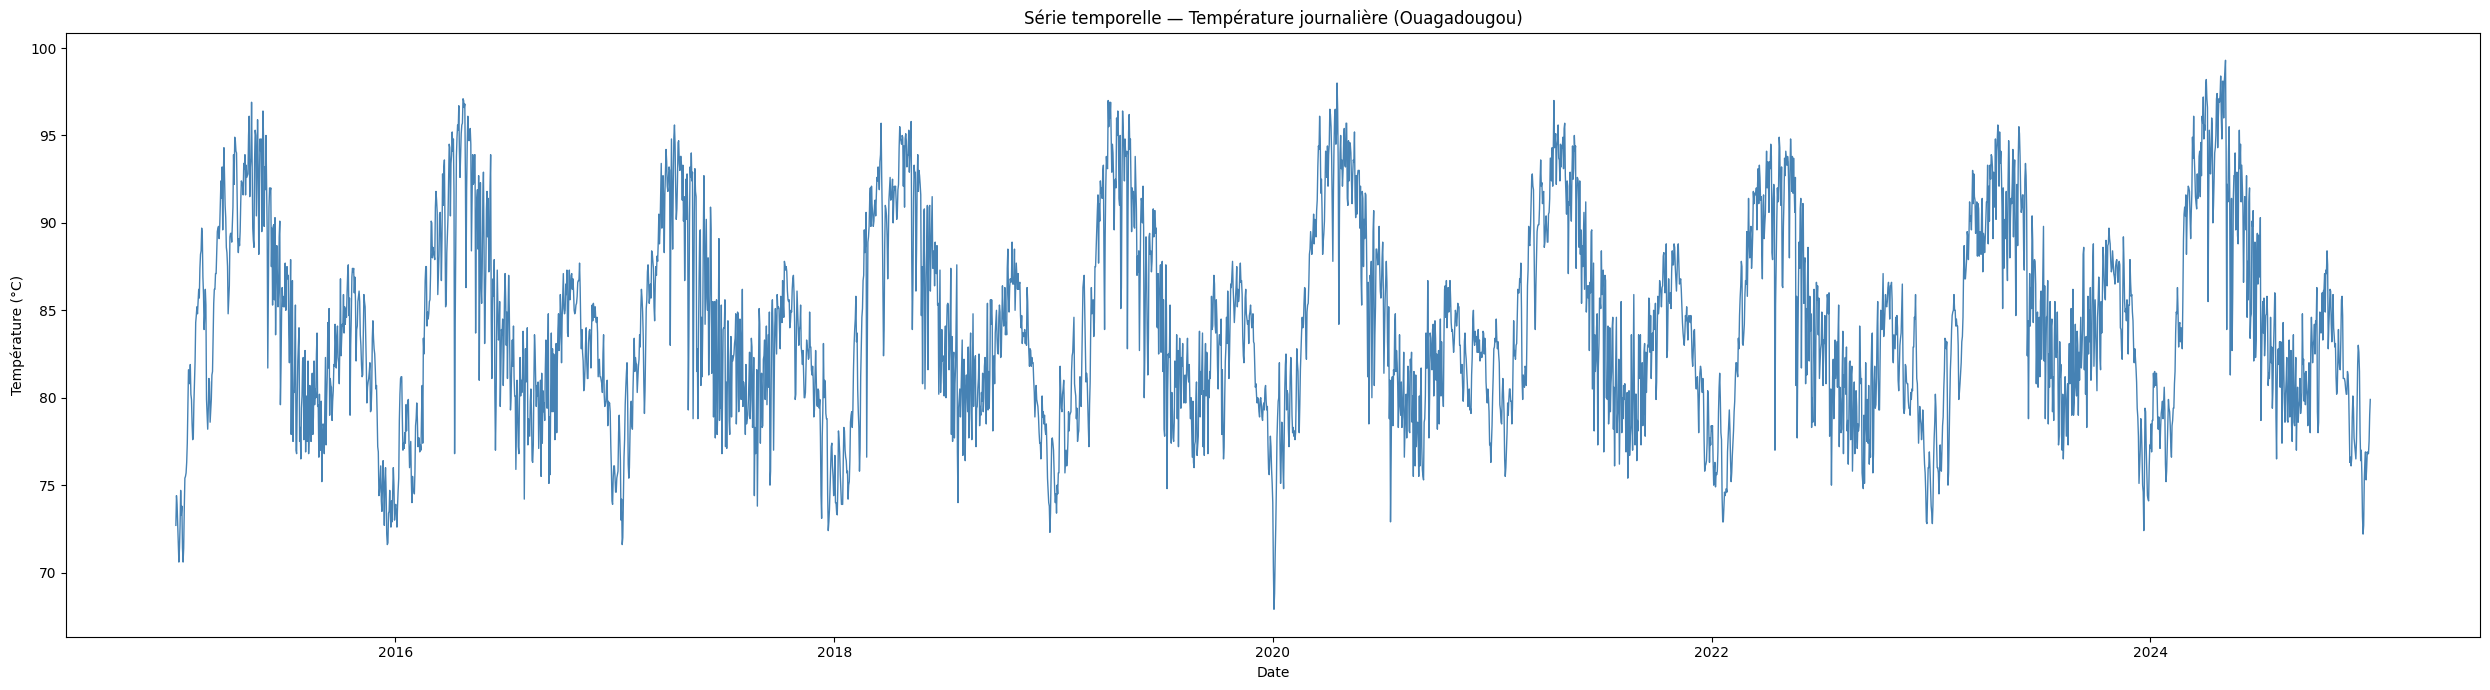

In [ ]:
plt.figure(figsize=(25, 7))
plt.plot(df_index, df_values, linewidth=1, color='steelblue')
plt.title('Série temporelle — Température journalière (Ouagadougou)')
plt.xlabel('Date')
plt.ylabel('Température (°C)')
plt.tight_layout()
plt.show()

# **Step 3 : Scaling Data**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(df_values)
print(f'data_scaled shape : {data_scaled.shape}')

data_scaled shape : (3658, 1)


In [ ]:
data_scaled[:5]

array([[0.15286624],
       [0.20700637],
       [0.1910828 ],
       [0.15605096],
       [0.12738854]])

In [ ]:
data_scaled.shape

(3658, 1)

In [ ]:
steps= 20
inp = []
out = []
for i in range(len(data_scaled) - (steps)):
    inp.append(data_scaled[i:i+steps])
    out.append(data_scaled[i+steps])

In [ ]:
out[:10]

[array([0.36942675]),
 array([0.43630573]),
 array([0.42356688]),
 array([0.41082803]),
 array([0.44585987]),
 array([0.39171975]),
 array([0.38216561]),
 array([0.33757962]),
 array([0.3089172]),
 array([0.31210191])]

reshape

In [ ]:
import numpy as np

In [ ]:
inp= np.asanyarray(inp)
out= np.asanyarray(out)

# **Step 4 : Split the dataset into training and testing sets**

In [ ]:
n_total   = len(df_values)
split_idx = int(len(inp) * 0.80)
print(f'Total : {n_total} obs  |  Train séquences : {split_idx}  |  Test séquences : {len(inp) - split_idx}')
print(f'Taille inp : {len(inp)}')

Total : 3658 obs  |  Train séquences : 2910  |  Test séquences : 728
Taille inp : 3638


In [ ]:
# Split dynamique (80/20) — ne pas coder l'indice en dur
split_idx = int(len(inp) * 0.80)

x_train = inp[:split_idx]
x_test  = inp[split_idx:]
y_train = out[:split_idx]
y_test  = out[split_idx:]

print(f'x_train : {x_train.shape}  |  x_test : {x_test.shape}')
print(f'y_train : {y_train.shape}  |  y_test : {y_test.shape}')

x_train : (2910, 20, 1)  |  x_test : (728, 20, 1)
y_train : (2910, 1)  |  y_test : (728, 1)


In [ ]:
inp.shape

(3638, 20, 1)

In [ ]:
x_train.shape

(2910, 20, 1)

In [ ]:
x_test.shape

(728, 20, 1)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.layers import Dense,RepeatVector, LSTM, Dropout
from tensorflow.keras.layers import Flatten, Conv1D, MaxPooling1D
from tensorflow.keras.layers import Bidirectional, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import plot_model

# **Step 5: Model Building**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(20, 1)),
    LSTM(50, return_sequences=True),
    LSTM(50),
    Dense(1)
])
model.compile(loss='mean_squared_error', optimizer='adam')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

# **Step 6: Training**

Epoch 1/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - loss: 0.0261 - val_loss: 0.0103 - learning_rate: 0.0010
Epoch 2/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0102 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 3/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0097 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 4/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0093 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 5/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0089 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 6/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.0088 - val_loss: 0.0091 - learning_rate: 0.0010
Epoch 7/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0089 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 8/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0080 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 9/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0080 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 10/3

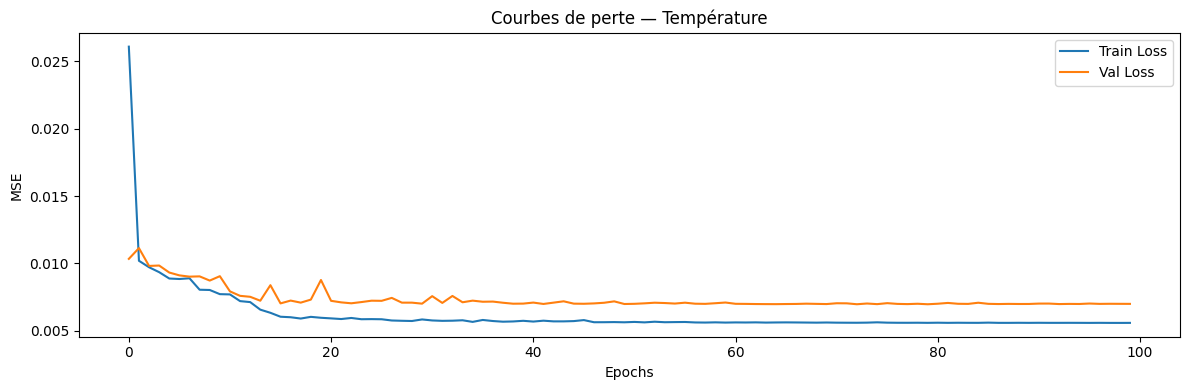

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)
]

history = model.fit(
    x_train, y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

# Courbes d'entraînement
plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Courbes de perte — Température')
plt.xlabel('Epochs'); plt.ylabel('MSE'); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
model.evaluate(x_test, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0057


0.005651694722473621

# **Step 7: Predictions and Model evaluation**

Predictions on training set

In [ ]:
print("Predicted Value",model.predict(x_train)[10][0])
print("Expected value",y_train[10][0])

91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Predicted Value 0.33718693
Expected value 0.37579617834394874


Predictions on testing set

In [ ]:
predictions=model.predict(x_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [ ]:
print("Predicted Value",predictions[2][0])
print("Expected Value",y_test[2][0])

Predicted Value 0.28641725
Expected Value 0.3407643312101909


In [ ]:
predictions.shape

(728, 1)

In [ ]:
y_test.shape

(728, 1)

In [ ]:
pred_df=pd.DataFrame(predictions)

In [ ]:
pred_df['TrueValues']=y_test

In [ ]:
pred_df_new = pred_df.rename(columns={ 0: 'Predictions'})

In [ ]:
pred_df_new

,Predictions,TrueValues
0,0.205499,0.267516
1,0.247673,0.312102
2,0.286417,0.340764
3,0.315089,0.391720
4,0.354023,0.366242
...,...,...
723,0.279763,0.283439
724,0.282551,0.283439
725,0.284832,0.305732
726,0.299124,0.353503


Text(0.5, 1.0, 'Predictions VS True Values on Testing Set')

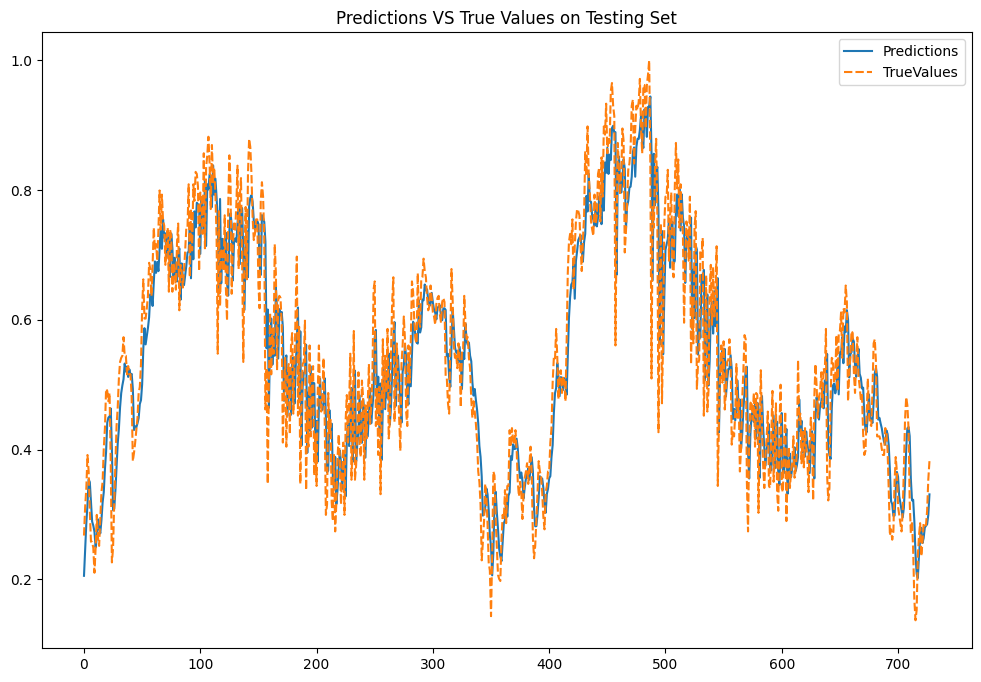

In [ ]:
plt.figure(figsize=(12,8))
sns.lineplot(data= pred_df_new)
plt.title("Predictions VS True Values on Testing Set")

# **Step 8: Calculate the evaluation metrices**

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Prédictions (espace normalisé)
y_pred_scaled = model.predict(x_test)

# Inverse transform → échelle originale (°C)
y_pred_orig = scaler.inverse_transform(y_pred_scaled)
y_test_orig = scaler.inverse_transform(y_test)

# Métriques sur l'échelle originale
mse  = mean_squared_error(y_test_orig, y_pred_orig)
mae  = mean_absolute_error(y_test_orig, y_pred_orig)
rmse = np.sqrt(mse)

# MAPE robuste (ignore les zéros)
mask = y_test_orig.flatten() != 0
mape = np.mean(np.abs((y_test_orig.flatten()[mask] - y_pred_orig.flatten()[mask])
                       / y_test_orig.flatten()[mask])) * 100

print("Métriques — Température (échelle originale °C)")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.4f} %")

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
MSE: 0.005651694674783199
MAE: 0.05778773696893003
RMSE: 0.07517775385566663
MAPE: 12.144299491078325


# **Step 9: Weather Predictions for next 30 Days**

In [ ]:
data_scaled.shape

(3658, 1)

In [ ]:
x_input=data_scaled[:20]

In [ ]:
x_input.shape

(20, 1)

In [ ]:
# now reshaping the data
x_input = x_input.reshape(1, -1)

In [ ]:
x_input.shape

(1, 20)

In [ ]:
# x_input = x_input.reshape((1, 20,1))
# yhat = model.predict(x_input, verbose=0)

In [ ]:
temp_input = list(x_input)
temp_input = temp_input[0].tolist()

In [ ]:
# demonstrate prediction
from numpy import array

lst_output=[]
n_steps=20
i=0
while(i<365):

    if(len(temp_input)>20):
        #print(temp_input)
        x_input=np.array(temp_input[1:])
        print("{} day input {}".format(i,x_input))
        x_input=x_input.reshape(1,-1)
        x_input = x_input.reshape((1, n_steps, 1))
        #print(x_input)
        yhat = model.predict(x_input, verbose=0)
        print("{} day output {}".format(i,yhat))
        temp_input.extend(yhat[0].tolist())
        temp_input=temp_input[1:]
        #print(temp_input)
        lst_output.extend(yhat.tolist())
        i=i+1
    else:
        x_input = x_input.reshape((1, n_steps,1))
        yhat = model.predict(x_input, verbose=0)
        print(yhat[0])
        temp_input.extend(yhat[0].tolist())
#         print(len(temp_input))
        lst_output.extend(yhat.tolist())
        i=i+1


print(lst_output)

[0.28666958]
1 day input [0.20700637 0.1910828  0.15605096 0.12738854 0.08598726 0.11146497
 0.15286624 0.21656051 0.17197452 0.18789809 0.11146497 0.08598726
 0.11146497 0.18471338 0.2388535  0.24203822 0.24840764 0.26751592
 0.30254777 0.28666958]
1 day output [[0.2861145]]
2 day input [0.1910828  0.15605096 0.12738854 0.08598726 0.11146497 0.15286624
 0.21656051 0.17197452 0.18789809 0.11146497 0.08598726 0.11146497
 0.18471338 0.2388535  0.24203822 0.24840764 0.26751592 0.30254777
 0.28666958 0.28611451]
2 day output [[0.28861022]]
3 day input [0.15605096 0.12738854 0.08598726 0.11146497 0.15286624 0.21656051
 0.17197452 0.18789809 0.11146497 0.08598726 0.11146497 0.18471338
 0.2388535  0.24203822 0.24840764 0.26751592 0.30254777 0.28666958
 0.28611451 0.28861022]
3 day output [[0.2919689]]
4 day input [0.12738854 0.08598726 0.11146497 0.15286624 0.21656051 0.17197452
 0.18789809 0.11146497 0.08598726 0.11146497 0.18471338 0.2388535
 0.24203822 0.24840764 0.26751592 0.30254777 0.28

In [ ]:
n_hist = len(data_scaled)
day_new  = np.arange(1, n_hist + 1)
day_pred = np.arange(n_hist + 1, n_hist + 366)
print(f'Historique : {n_hist} jours  |  Prévision : 365 jours')

Historique : 3658 jours  |  Prévision : 365 jours


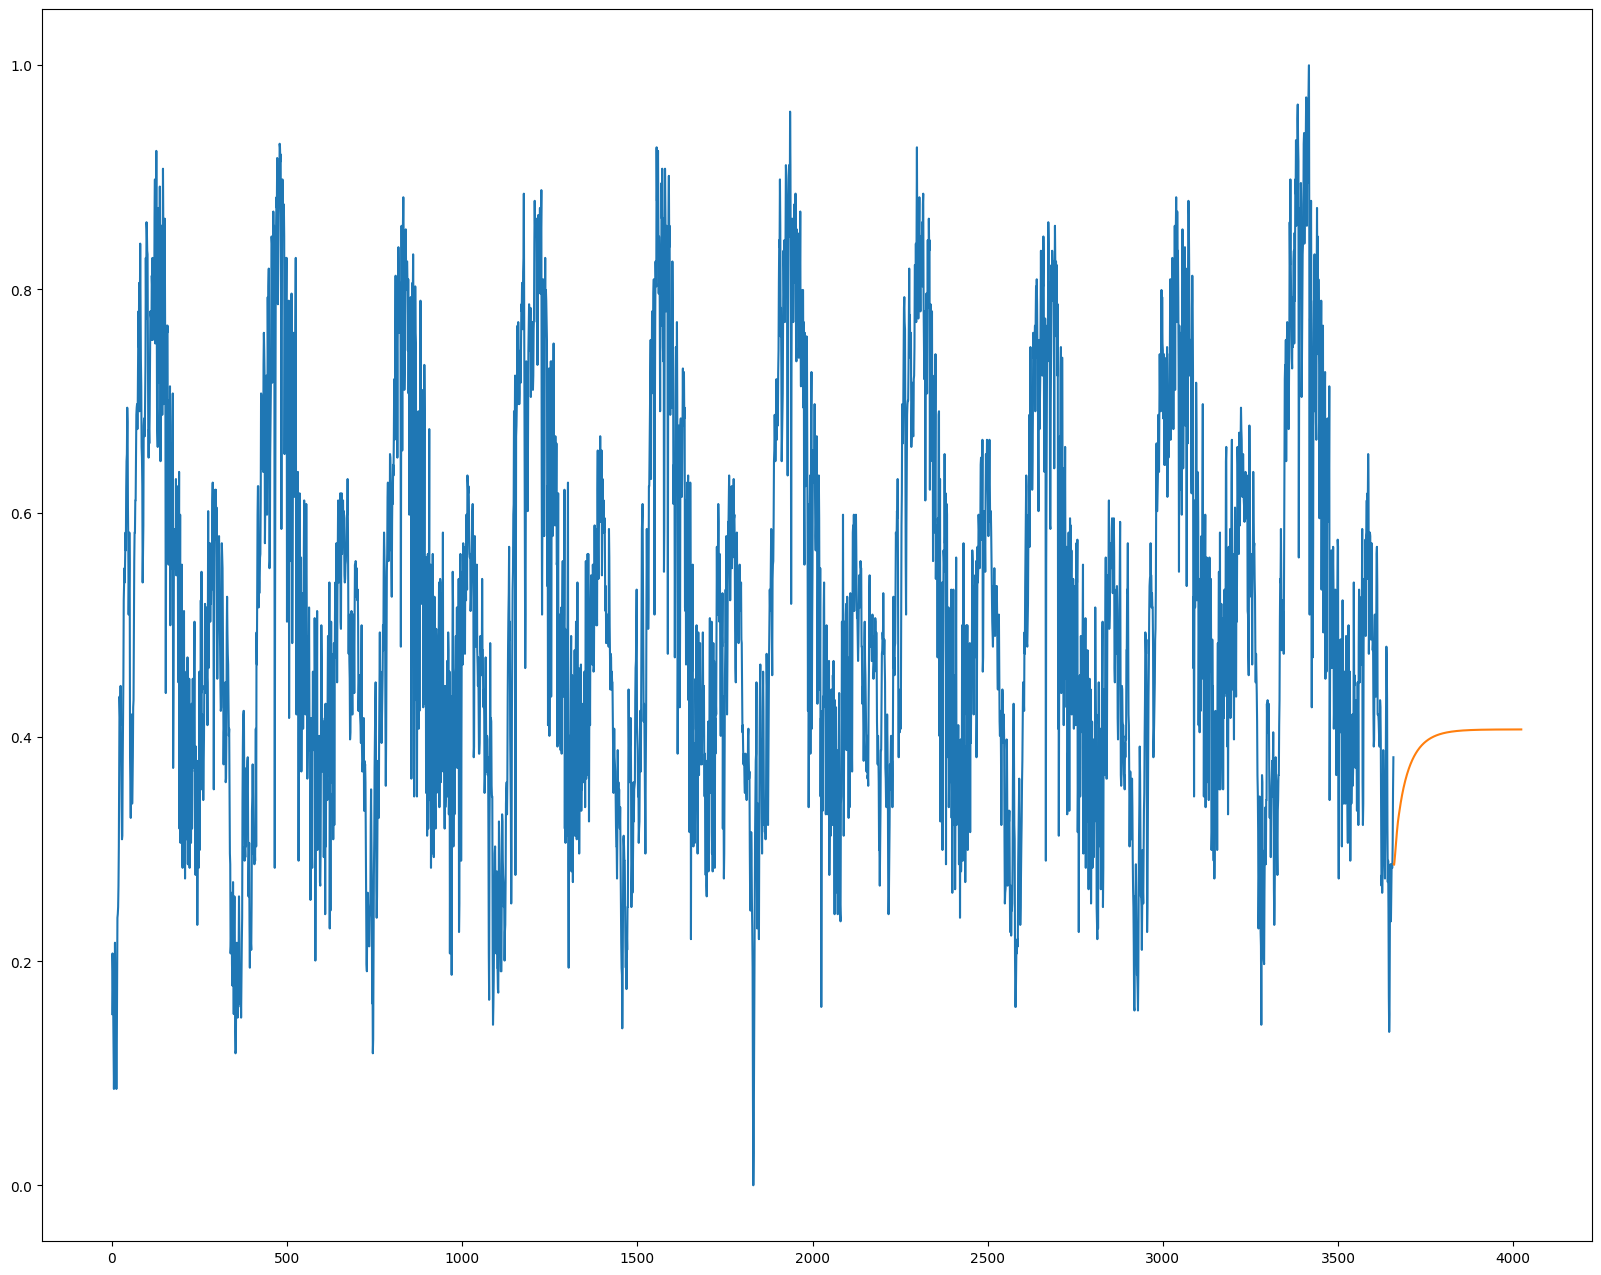

In [ ]:
plt.figure(figsize=(20,16))
plt.plot(day_new,data_scaled)
plt.plot(day_pred,lst_output)

In [ ]:
data_scaled[:5]

array([[0.15286624],
       [0.20700637],
       [0.1910828 ],
       [0.15605096],
       [0.12738854]])

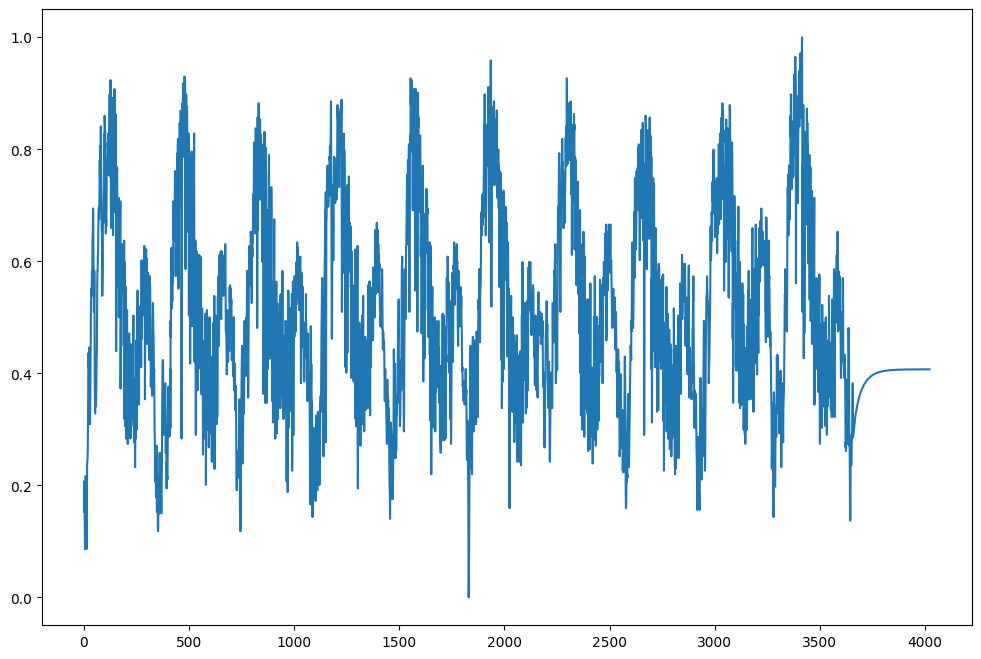

In [ ]:
df3 = data_scaled.tolist()
df3.extend(lst_output)
plt.figure(figsize=(12,8))
plt.plot(df3)

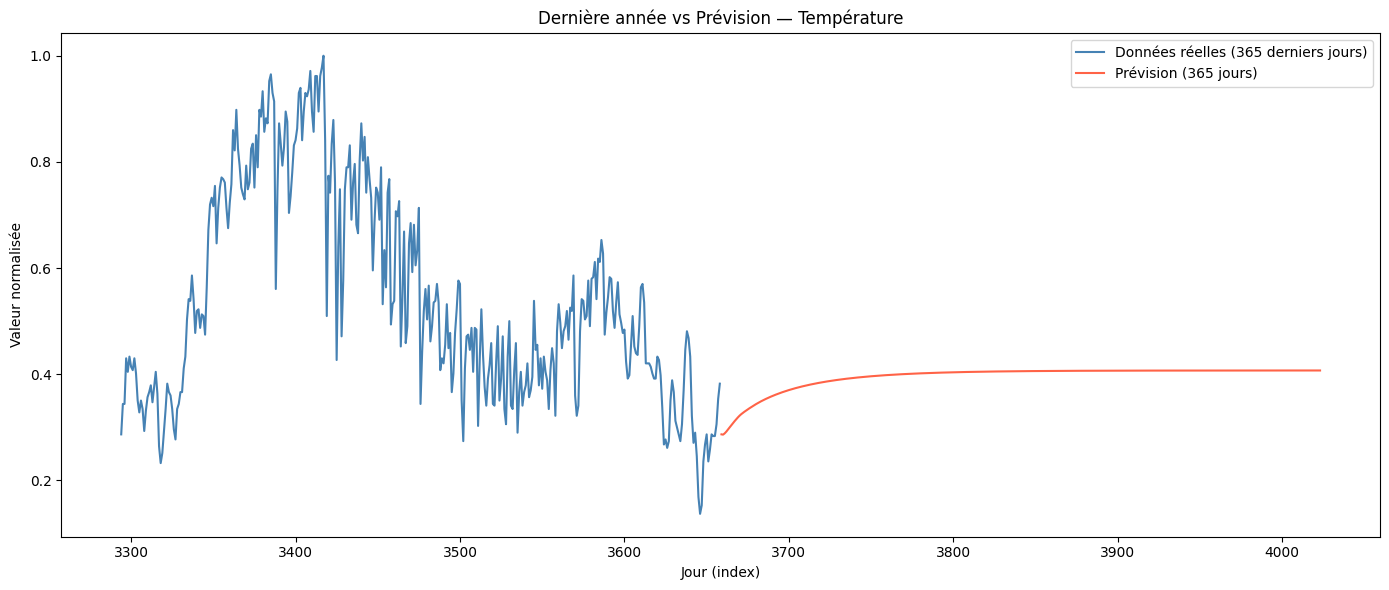

In [ ]:
# Axes des vrais jours
last_year_days = day_new[-365:]
last_year_data = data_scaled[-365:]
forecast_data  = lst_output

plt.figure(figsize=(14, 6))
plt.plot(last_year_days, last_year_data, label='Données réelles (365 derniers jours)', color='steelblue')
plt.plot(day_pred,       forecast_data,  label='Prévision (365 jours)',               color='tomato')
plt.xlabel('Jour (index)')
plt.ylabel('Valeur normalisée')
plt.legend()
plt.title('Dernière année vs Prévision — Température')
plt.tight_layout(); plt.show()

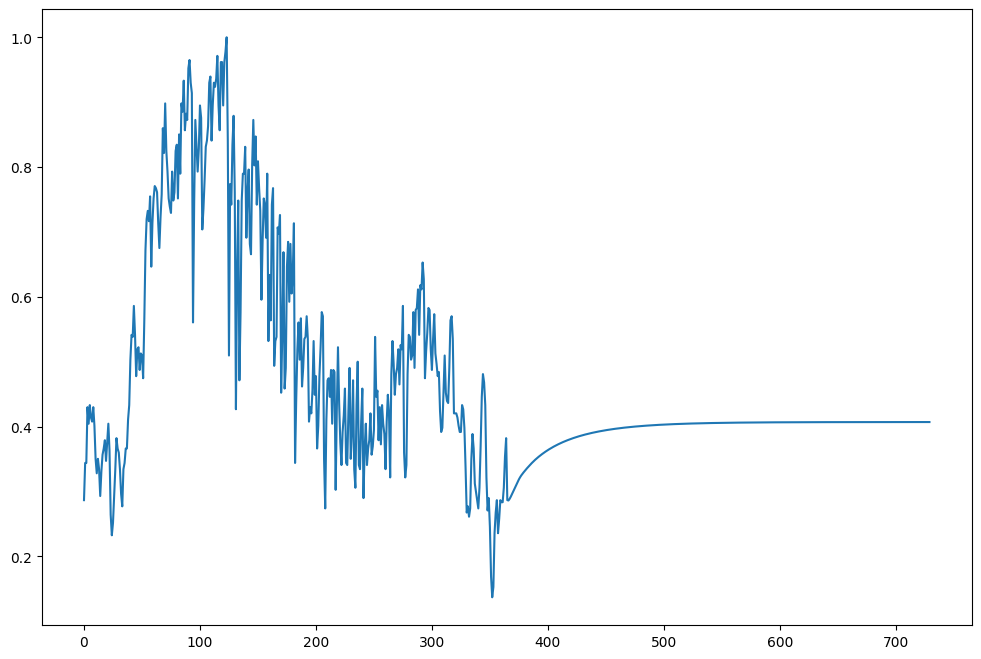

In [ ]:
df3 = data_scaled[-365:].tolist()
df3.extend(lst_output)
plt.figure(figsize=(12,8))
plt.plot(df3)

In [ ]:
# # Check lengths of arrays
# print("Length of last_year_days:", len(last_year_days))
# print("Length of last_year_data_original:", len(last_year_data_original))
# print("Length of day_pred:", len(day_pred))
# print("Length of forecast_data_original:", len(forecast_data_original))

Aperçu des prévisions température :
          Date  Actual  Predicted
720 2025-12-23     NaN  80.679640
721 2025-12-24     NaN  80.679663
722 2025-12-25     NaN  80.679679
723 2025-12-26     NaN  80.679702
724 2025-12-27     NaN  80.679716
725 2025-12-28     NaN  80.679735
726 2025-12-29     NaN  80.679753
727 2025-12-30     NaN  80.679774
728 2025-12-31     NaN  80.679787
729 2026-01-01     NaN  80.679800


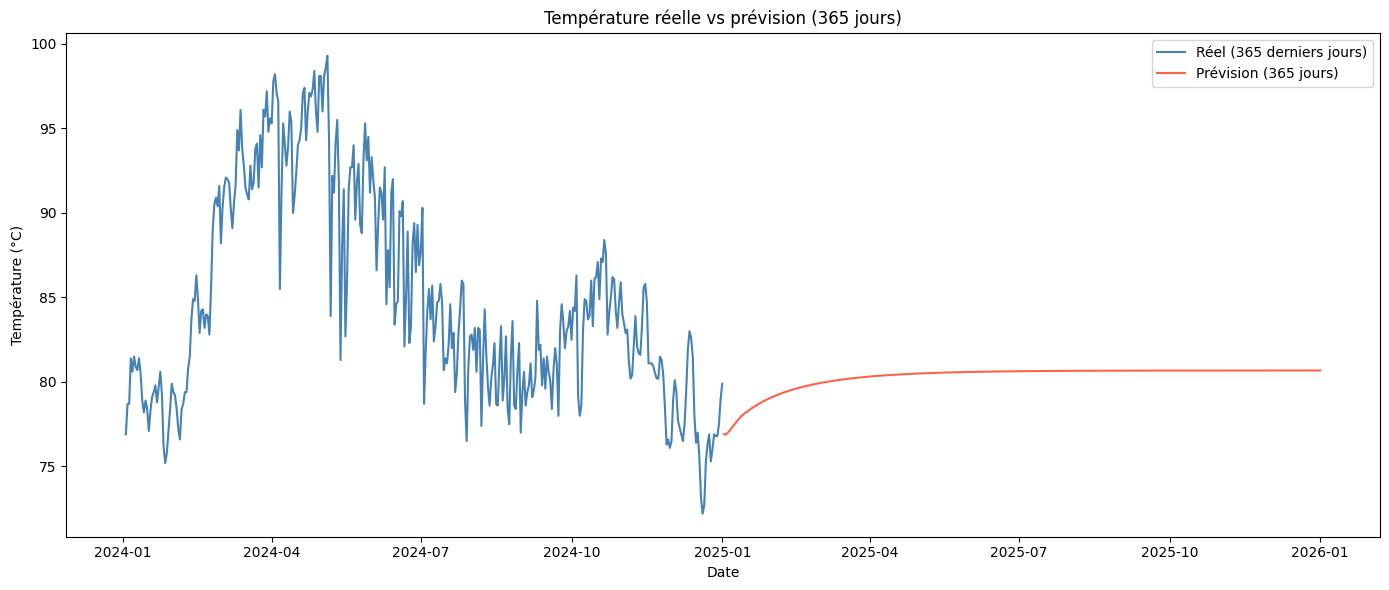

In [ ]:
last_year_data = data_scaled[-365:]
forecast_data  = lst_output

# Inverse transform vers l'échelle originale
last_year_data_original = scaler.inverse_transform(np.array(last_year_data).reshape(-1, 1))
forecast_data_original  = scaler.inverse_transform(np.array(forecast_data).reshape(-1, 1))

# Dates réelles depuis df_index conservé
last_date    = df_index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=365, freq='D')

actual_vs_predicted_df = pd.DataFrame({
    'Date':      list(df_index[-365:]) + list(future_dates),
    'Actual':    list(last_year_data_original.flatten()) + [np.nan] * 365,
    'Predicted': [np.nan] * 365 + list(forecast_data_original.flatten())
})

print('Aperçu des prévisions température :')
print(actual_vs_predicted_df.tail(10))

plt.figure(figsize=(14, 6))
plt.plot(actual_vs_predicted_df['Date'], actual_vs_predicted_df['Actual'],
         label='Réel (365 derniers jours)', color='steelblue')
plt.plot(actual_vs_predicted_df['Date'], actual_vs_predicted_df['Predicted'],
         label='Prévision (365 jours)', color='tomato')
plt.title('Température réelle vs prévision (365 jours)')
plt.xlabel('Date'); plt.ylabel('Température (°C)'); plt.legend()
plt.tight_layout(); plt.show()

# **Rainfall**

In [ ]:
# Recharger le dataset original (avant la réduction à une colonne)
df_raw = pd.concat([pd.read_csv(f) for f in sorted(glob.glob('data-0*.csv'))], ignore_index=True)
df_raw['datetime'] = pd.to_datetime(df_raw['datetime'])
df_raw = df_raw.sort_values('datetime').reset_index(drop=True)
print(df_raw[['datetime', 'precip']].head())
print(f'Shape : {df_raw.shape}')

    datetime  precip
0 2015-01-01     0.0
1 2015-01-02     0.0
2 2015-01-03     0.0
3 2015-01-04     0.0
4 2015-01-05     0.0
Shape : (3658, 33)


In [ ]:
# DataFrame rainfall avec DatetimeIndex
df_rainfall = pd.DataFrame(
    df_raw['precip'].values,
    index=pd.DatetimeIndex(df_raw['datetime']),
    columns=['rain']
)
print(f'Shape : {df_rainfall.shape}')
df_rainfall.head()

Shape : (3658, 1)


,rain
datetime,
2015-01-01,0.0
2015-01-02,0.0
2015-01-03,0.0
2015-01-04,0.0
2015-01-05,0.0


In [ ]:
df_rainfall.head()

,rain
datetime,
2015-01-01,0.0
2015-01-02,0.0
2015-01-03,0.0
2015-01-04,0.0
2015-01-05,0.0


In [ ]:
df_rainfall.isnull().sum()

,0
rain,0


In [ ]:
df_rainfall = df_rainfall.dropna(axis=0)
print(f'Shape après dropna : {df_rainfall.shape}')
df_rainfall.isnull().sum()

Shape après dropna : (3658, 1)


,0
rain,0


In [ ]:
df_rainfall.shape

(3658, 1)

In [ ]:
# Conserver le DatetimeIndex pour les plots et le résultat final
df_rainfall_index = df_rainfall.index.copy()

# Tableau numpy pour le scaler et les séquences LSTM
df_rainfall_values = df_rainfall['rain'].values.reshape(-1, 1)
print(f'df_rainfall_values shape : {df_rainfall_values.shape}')

df_rainfall_values shape : (3658, 1)


In [ ]:
df_rainfall_values[:5]

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [ ]:
# df_rainfall_values déjà reshapé (-1, 1) à l'étape précédente
print(f'Shape confirmé : {df_rainfall_values.shape}')

Shape confirmé : (3658, 1)


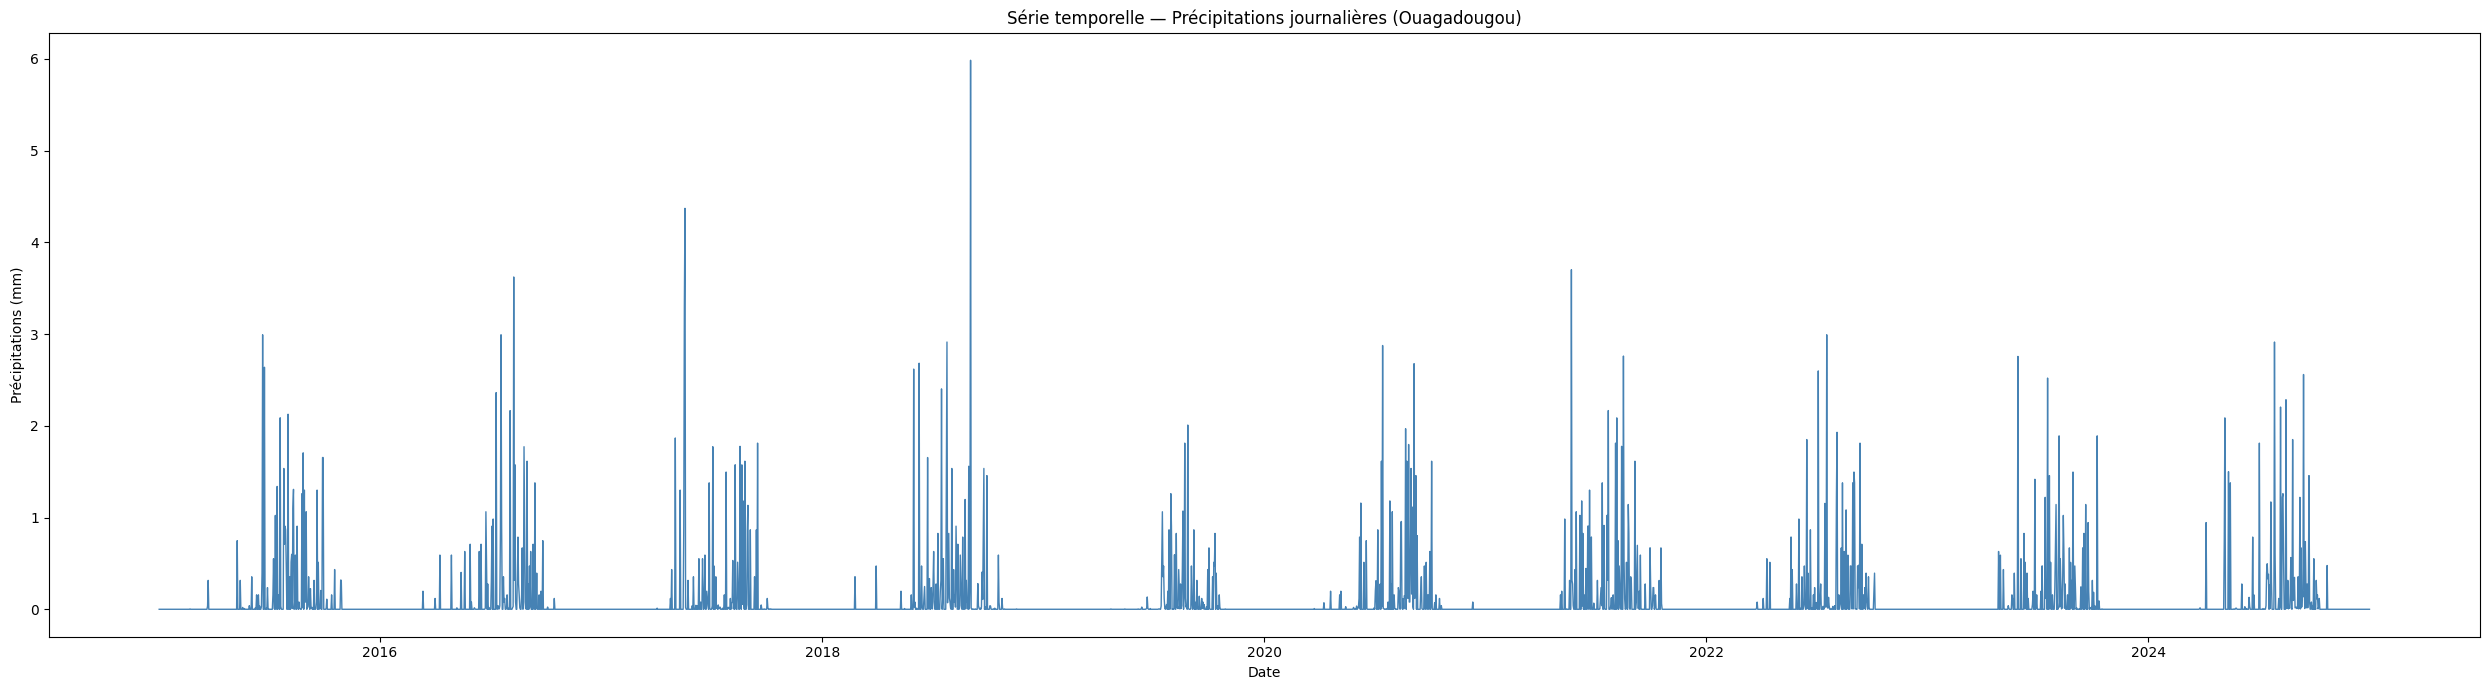

In [ ]:
plt.figure(figsize=(25, 7))
plt.plot(df_rainfall_index, df_rainfall_values, linewidth=1, color='steelblue')
plt.title('Série temporelle — Précipitations journalières (Ouagadougou)')
plt.xlabel('Date')
plt.ylabel('Précipitations (mm)')
plt.tight_layout()
plt.show()

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(df_rainfall_values)
print(f'data_scaled shape : {data_scaled.shape}')

data_scaled shape : (3658, 1)


In [ ]:
data_scaled[:5]

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [ ]:
data_scaled.shape

(3658, 1)

In [ ]:
steps= 20
inp = []
out = []
for i in range(len(data_scaled) - (steps)):
    inp.append(data_scaled[i:i+steps])
    out.append(data_scaled[i+steps])

out[:10]

[array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.])]

In [ ]:
inp= np.asanyarray(inp)
out= np.asanyarray(out)

In [ ]:
n_total_rf   = len(df_rainfall_values)
split_idx_rf = int(len(inp) * 0.80)
print(f'Total : {n_total_rf}  |  Train séquences : {split_idx_rf}  |  Test : {len(inp) - split_idx_rf}')
print(f'Taille inp : {len(inp)}')

Total : 3658  |  Train séquences : 2910  |  Test : 728
Taille inp : 3638


In [ ]:
split_idx_rf = int(len(inp) * 0.80)

x_train_rainfall = inp[:split_idx_rf]
x_test_rainfall  = inp[split_idx_rf:]
y_train_rainfall = out[:split_idx_rf]
y_test_rainfall  = out[split_idx_rf:]

print(f'x_train_rainfall : {x_train_rainfall.shape}  |  x_test_rainfall : {x_test_rainfall.shape}')

x_train_rainfall : (2910, 20, 1)  |  x_test_rainfall : (728, 20, 1)


In [ ]:
print(x_train_rainfall.shape, x_test_rainfall.shape)

(2910, 20, 1) (728, 20, 1)


In [ ]:
model_rainfall = Sequential([
    LSTM(50, return_sequences=True, input_shape=(20, 1)),
    LSTM(50, return_sequences=True),
    LSTM(50),
    Dense(1)
])
model_rainfall.compile(loss='mean_squared_error', optimizer='adam')
model_rainfall.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 20, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 20, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 0.0037 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 2/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0037 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 3/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0036 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 4/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0036 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 5/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0036 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 6/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0036 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 7/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0036 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 8/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0036 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 9/300
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0036 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 10/3

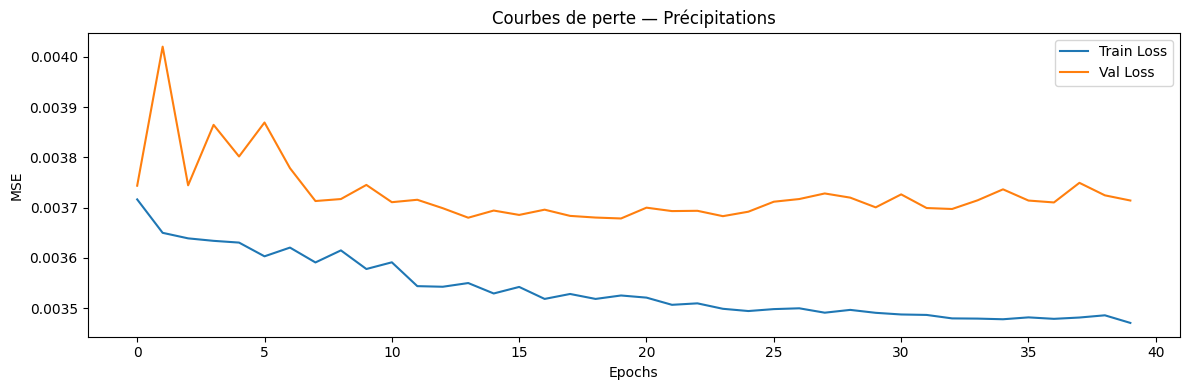

In [ ]:
callbacks_rf = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)
]

history_rf = model_rainfall.fit(
    x_train_rainfall, y_train_rainfall,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks_rf,
    verbose=1
)

plt.figure(figsize=(12, 4))
plt.plot(history_rf.history['loss'],     label='Train Loss')
plt.plot(history_rf.history['val_loss'], label='Val Loss')
plt.title('Courbes de perte — Précipitations')
plt.xlabel('Epochs'); plt.ylabel('MSE'); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
model_rainfall.evaluate(x_test_rainfall, y_test_rainfall)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0032


0.003153204917907715

In [ ]:
print("Predicted Value",model_rainfall.predict(x_train_rainfall)[10][0])
print("Expected value",y_train_rainfall[10][0])

91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Predicted Value -0.00024268217
Expected value 0.0


In [ ]:
predictions_rainfall=model_rainfall.predict(x_test_rainfall)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [ ]:
pred_df_rainfall=pd.DataFrame(predictions_rainfall)

In [ ]:
pred_df_rainfall['TrueValues']=y_test_rainfall

In [ ]:
pred_df_new_rainfall = pred_df_rainfall.rename(columns={ 0: 'Predictions_rainfall'})

In [ ]:
pred_df_new_rainfall

,Predictions_rainfall,TrueValues
0,-0.000243,0.0
1,-0.000243,0.0
2,-0.000243,0.0
3,-0.000243,0.0
4,-0.000243,0.0
...,...,...
723,-0.000243,0.0
724,-0.000243,0.0
725,-0.000243,0.0
726,-0.000243,0.0


Text(0.5, 1.0, 'Predictions VS True Values on Testing Set')

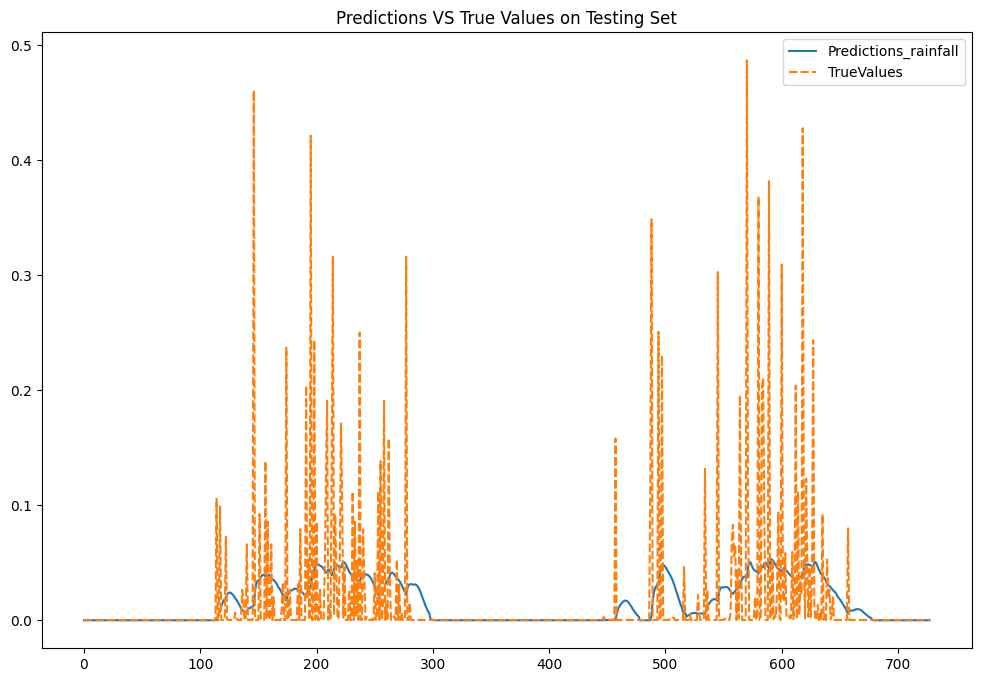

In [ ]:
plt.figure(figsize=(12,8))
sns.lineplot(data= pred_df_new_rainfall)
plt.title("Predictions VS True Values on Testing Set")

In [ ]:
# Prédictions (espace normalisé)
y_pred_rainfall_scaled = model_rainfall.predict(x_test_rainfall)

# Inverse transform → échelle originale (mm)
y_pred_rf_orig = scaler.inverse_transform(y_pred_rainfall_scaled)
y_test_rf_orig = scaler.inverse_transform(y_test_rainfall)

# Métriques sur l'échelle originale
mse  = mean_squared_error(y_test_rf_orig, y_pred_rf_orig)
mae  = mean_absolute_error(y_test_rf_orig, y_pred_rf_orig)
rmse = np.sqrt(mse)

# MAPE robuste (précipitations = 0 fréquents → ignorer)
mask_rf = y_test_rf_orig.flatten() != 0
if mask_rf.sum() > 0:
    mape = np.mean(np.abs((y_test_rf_orig.flatten()[mask_rf] - y_pred_rf_orig.flatten()[mask_rf])
                           / y_test_rf_orig.flatten()[mask_rf])) * 100
else:
    mape = np.nan

print("Métriques — Précipitations (échelle originale mm)")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.4f} %" if not np.isnan(mape) else "MAPE : N/A (trop de zéros)")

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
MSE: 0.003153204785493506
MAE: 0.023247410894752813
RMSE: 0.05615340404190565
MAPE: 3516455548311537.5


In [ ]:
x_input_rainfall = data_scaled[:20]
print(f'x_input_rainfall shape : {x_input_rainfall.shape}')

x_input_rainfall shape : (20, 1)


In [ ]:
# now reshaping the data
x_input_rainfall = x_input_rainfall.reshape(1, -1)
x_input_rainfall.shape

(1, 20)

In [ ]:
temp_input_rainfall = list(x_input_rainfall)
temp_input_rainfall = temp_input_rainfall[0].tolist()

In [ ]:
lst_output_rainfall=[]
n_steps=20
i=0
while(i<365):

    if(len(temp_input_rainfall)>20):
        #print(temp_input)
        x_input_rainfall=np.array(temp_input_rainfall[1:])
        print("{} day input {}".format(i,x_input_rainfall))
        x_input_rainfall=x_input_rainfall.reshape(1,-1)
        x_input_rainfall = x_input_rainfall.reshape((1, n_steps, 1))
        #print(x_input)
        yhat_rainfall = model_rainfall.predict(x_input_rainfall, verbose=0)
        print("{} day output {}".format(i,yhat_rainfall))
        temp_input_rainfall.extend(yhat_rainfall[0].tolist())
        temp_input_rainfall=temp_input_rainfall[1:]
        #print(temp_input)
        lst_output_rainfall.extend(yhat_rainfall.tolist())
        i=i+1
    else:
        x_input_rainfall = x_input_rainfall.reshape((1, n_steps,1))
        yhat_rainfall = model_rainfall.predict(x_input_rainfall, verbose=0)
        print(yhat_rainfall[0])
        temp_input_rainfall.extend(yhat_rainfall[0].tolist())
#         print(len(temp_input))
        lst_output_rainfall.extend(yhat_rainfall.tolist())
        i=i+1


print(lst_output_rainfall)

[-0.00024268]
1 day input [ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.         -0.00024268]
1 day output [[-0.00025065]]
2 day input [ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.00024268 -0.00025065]
2 day output [[-0.00026542]]
3 day input [ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.         -0.00024268
 -0.00025065 -0.00026542]
3 day output [[-0.00028556]]
4 day input [ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.         -

In [ ]:
n_hist_rf = len(data_scaled)
day_new_rainfall  = np.arange(1, n_hist_rf + 1)
day_pred_rainfall = np.arange(n_hist_rf + 1, n_hist_rf + 366)
print(f'Historique : {n_hist_rf} jours  |  Prévision : 365 jours')

Historique : 3658 jours  |  Prévision : 365 jours


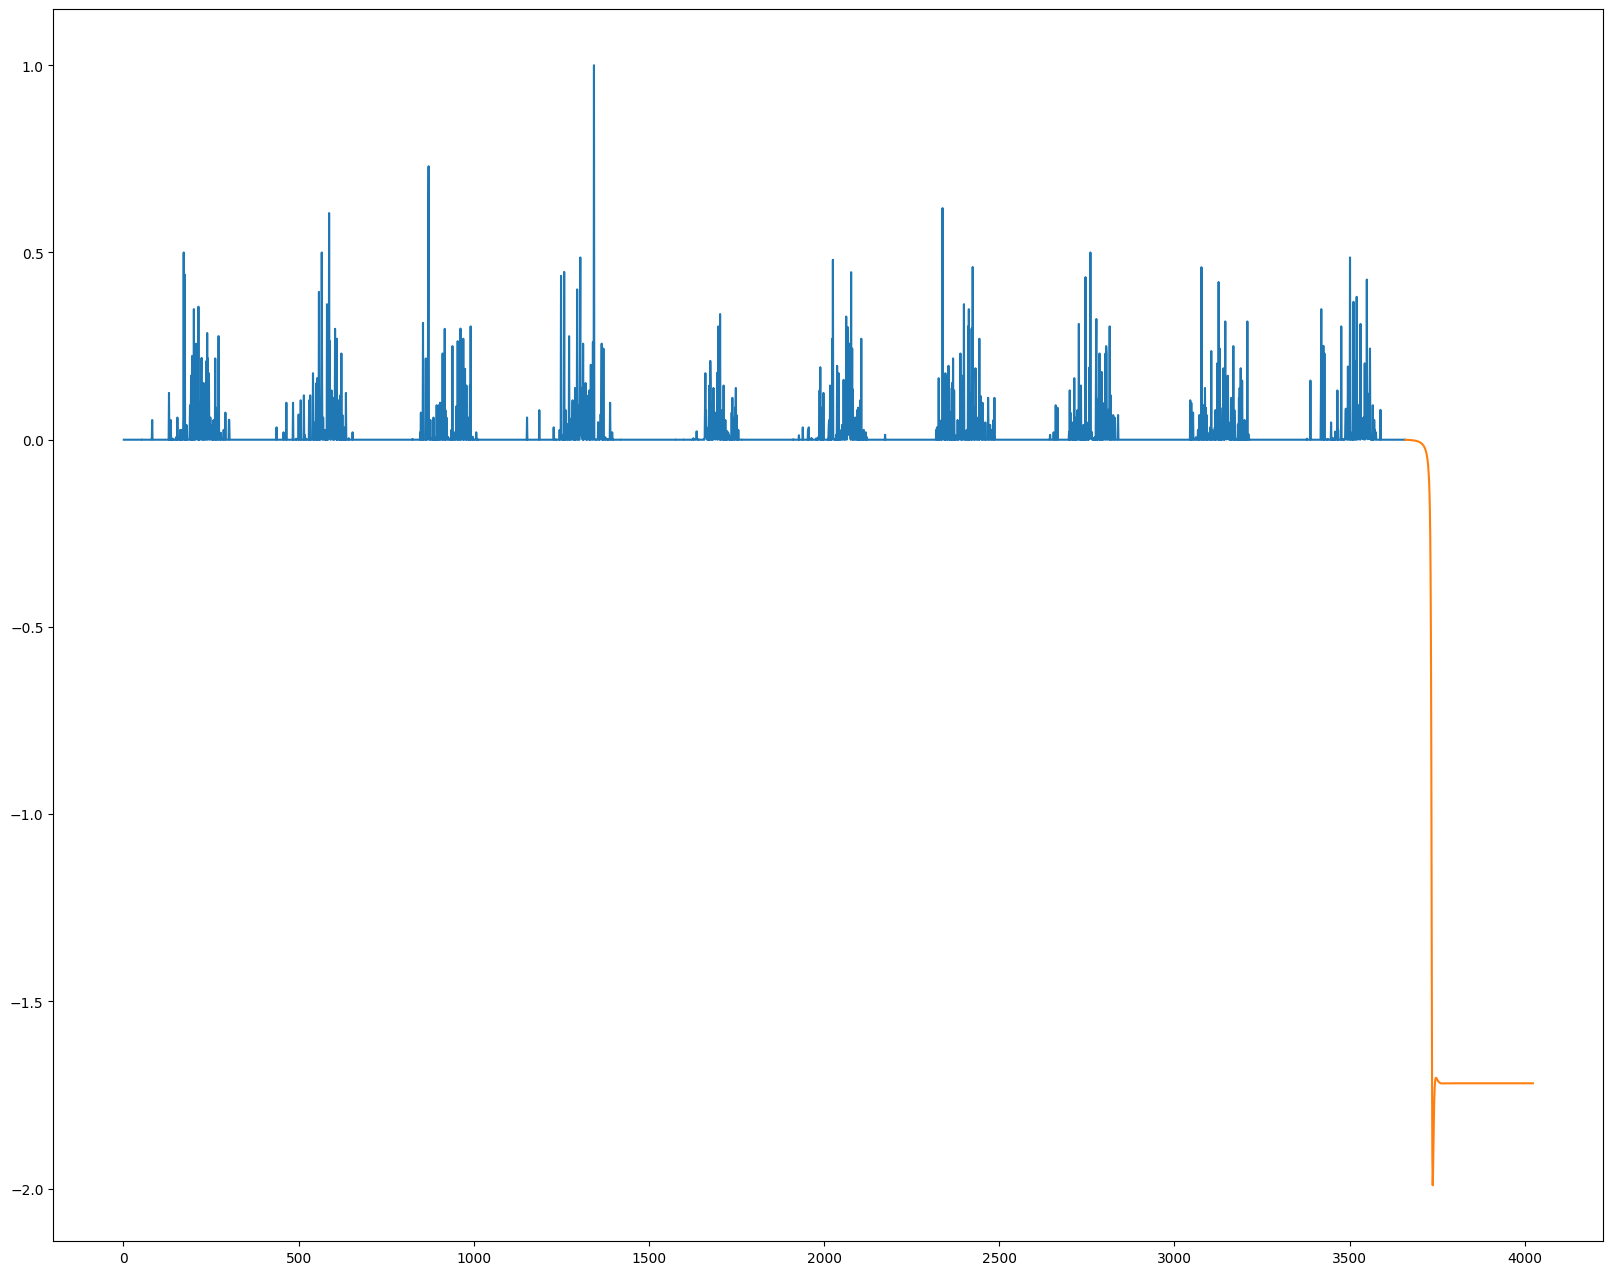

In [ ]:
plt.figure(figsize=(20,16))
plt.plot(day_new_rainfall,data_scaled)
plt.plot(day_pred_rainfall,lst_output_rainfall)

In [ ]:
data_scaled[:5]

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]])

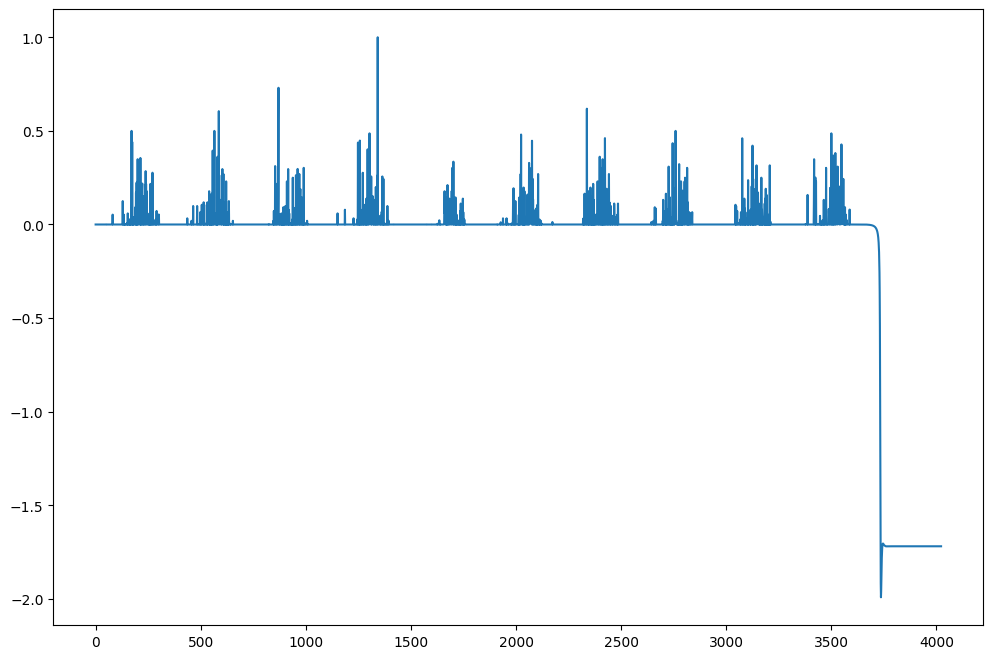

In [ ]:
df3_rainfall = data_scaled.tolist()
df3_rainfall.extend(lst_output_rainfall)
plt.figure(figsize=(12,8))
plt.plot(df3_rainfall)

In [ ]:
print('Length of day_new_rainfall    :', len(day_new_rainfall))
print('Length of day_pred_rainfall   :', len(day_pred_rainfall))
print('Length of lst_output_rainfall :', len(lst_output_rainfall))

Length of day_new_rainfall    : 3658
Length of day_pred_rainfall   : 365
Length of lst_output_rainfall : 365


Aperçu des prévisions précipitations :
          Date  Actual  Predicted
720 2025-12-23     NaN -10.285284
721 2025-12-24     NaN -10.285284
722 2025-12-25     NaN -10.285284
723 2025-12-26     NaN -10.285284
724 2025-12-27     NaN -10.285283
725 2025-12-28     NaN -10.285285
726 2025-12-29     NaN -10.285284
727 2025-12-30     NaN -10.285284
728 2025-12-31     NaN -10.285284
729 2026-01-01     NaN -10.285284


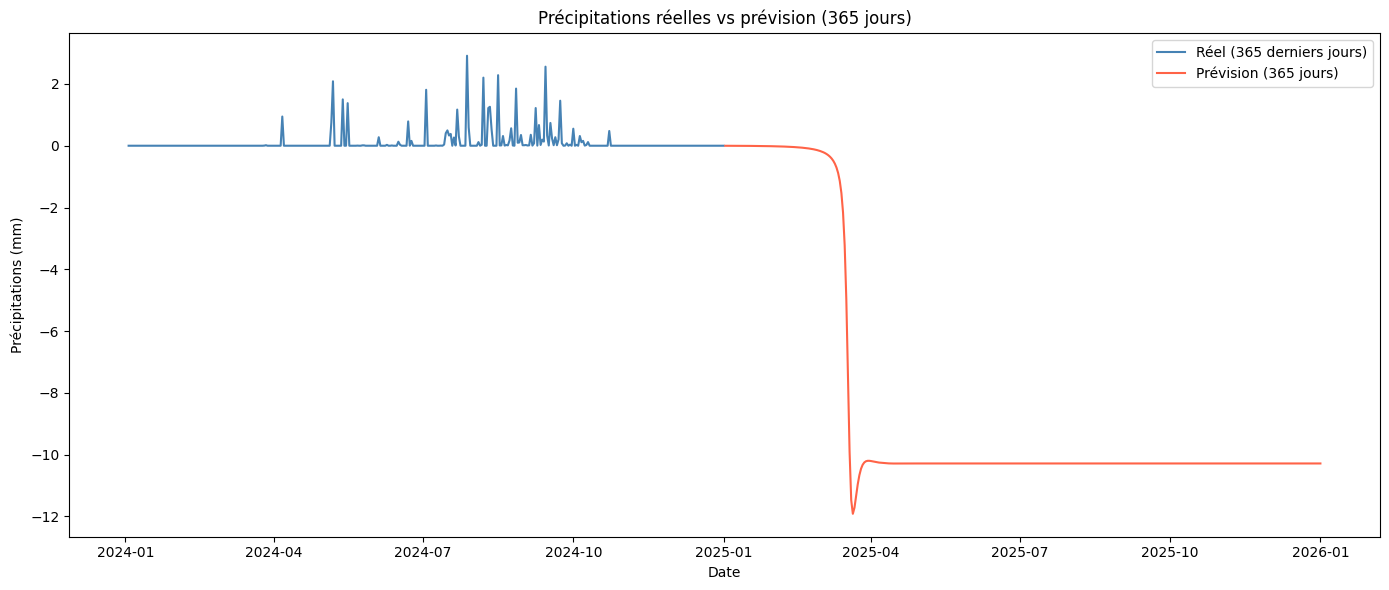

In [ ]:
last_year_data_rf = data_scaled[-365:]
forecast_data_rf  = lst_output_rainfall

# Inverse transform
last_year_data_rf_orig = scaler.inverse_transform(np.array(last_year_data_rf).reshape(-1, 1))
forecast_data_rf_orig  = scaler.inverse_transform(np.array(forecast_data_rf).reshape(-1, 1))

# Dates réelles depuis df_rainfall_index conservé
last_date_rf    = df_rainfall_index[-1]
future_dates_rf = pd.date_range(start=last_date_rf + pd.Timedelta(days=1), periods=365, freq='D')

actual_vs_predicted_rf = pd.DataFrame({
    'Date':      list(df_rainfall_index[-365:]) + list(future_dates_rf),
    'Actual':    list(last_year_data_rf_orig.flatten()) + [np.nan] * 365,
    'Predicted': [np.nan] * 365 + list(forecast_data_rf_orig.flatten())
})

print('Aperçu des prévisions précipitations :')
print(actual_vs_predicted_rf.tail(10))

plt.figure(figsize=(14, 6))
plt.plot(actual_vs_predicted_rf['Date'], actual_vs_predicted_rf['Actual'],
         label='Réel (365 derniers jours)', color='steelblue')
plt.plot(actual_vs_predicted_rf['Date'], actual_vs_predicted_rf['Predicted'],
         label='Prévision (365 jours)', color='tomato')
plt.title('Précipitations réelles vs prévision (365 jours)')
plt.xlabel('Date'); plt.ylabel('Précipitations (mm)'); plt.legend()
plt.tight_layout(); plt.show()

# **Thanks You**